# **Data Preparation**

In [ ]:
import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px

# Download the dataset
path = kagglehub.dataset_download("navenkumar1998/formula-1-dataset-with-weather-and-tyre-features")
print(" dataset downloaded to:", path)


print("\n Files in the dataset:")
files = os.listdir(path)
print(files)


csv_files = [f for f in files if f.endswith('.csv')]
print("\nCSV files found:", csv_files)


if len(csv_files) == 1:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print("\n data loaded successfully!")
    print("shape:", df.shape)
    print("\ncolumns:", df.columns.tolist())
    display(df.head())
    display(df.info())
elif len(csv_files) > 1:
    print("\nwe gonna chooce one ")
else:
    print("مفيش CSV يبويا")

 dataset downloaded to: /root/.cache/kagglehub/datasets/navenkumar1998/formula-1-dataset-with-weather-and-tyre-features/versions/1

 Files in the dataset:
['f1_all.parquet']

CSV files found: []
مفيش CSV يبويا


# **data understanding**

In [ ]:
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

print("🏎️ F1 Tire Project - Real Data")
df = pd.read_parquet(os.path.join(path, "f1_all.parquet"))
# creatin target column
df['tire_status'] = np.where(
    (df['TyreLife'] <= 15) & (df['FreshTyre'] == True), 'optimal',
    np.where(df['TyreLife'] <= 40, 'marginal', 'critical')
)


print(" data was uploaded successfully")

print("\n1.1.3 Size of Data")
print(f"num of rows: {df.shape[0]:,}")
print(f"num of columns: {df.shape[1]}")

print("\n1.1.5 name of columns :")
print(df.columns.tolist())

print("\n first 5 columns: ")
display(df.head())

print("\n 1.1.4 data info:")
df.info()

print("\n1.1.6 Check Description")
display(df.describe())

print("\n1.1.2 Random Sample Data")
display(df.sample(5))

print("\n1.1.7 Number of Unique Columns")
print(df.nunique())

print("\n1.1.8 Check Balance Of Data (Target = tire_status)")
print(df['tire_status'].value_counts(normalize=True) * 100)

#data is imbalance cuz of "critical" so low


🏎️ F1 Tire Project - Real Data
 data was uploaded successfully

1.1.3 Size of Data
num of rows: 69,230
num of columns: 30

1.1.5 name of columns :
['raceId', 'driverId', 'lap', 'position_x', 'time', 'milliseconds', 'year', 'round', 'circuitId', 'name', 'position_y', 'grid', 'constructorId', 'statusId', 'status', 'code', 'Driver', 'LapNumber', 'Compound', 'TyreLife', 'FreshTyre', 'Stint', 'AirTemp', 'TrackTemp', 'Humidity', 'Pressure', 'Rainfall', 'WindSpeed', 'WindDirection', 'tire_status']

 first 5 columns: 


,raceId,driverId,lap,position_x,time,milliseconds,year,round,circuitId,name,...,FreshTyre,Stint,AirTemp,TrackTemp,Humidity,Pressure,Rainfall,WindSpeed,WindDirection,tire_status
0,1052,830,1,1,1:58.245,118245,2021,1,3,Bahrain International Circuit,...,False,1.0,20.5,27.6,54.6,1014.9,0.0,0.9,11.0,marginal
1,1052,830,2,1,2:22.406,142406,2021,1,3,Bahrain International Circuit,...,False,1.0,20.5,27.6,54.6,1014.9,0.0,0.9,11.0,marginal
2,1052,830,3,1,2:38.001,158001,2021,1,3,Bahrain International Circuit,...,False,1.0,20.5,27.6,54.6,1014.9,0.0,0.9,11.0,marginal
3,1052,830,4,1,1:44.343,104343,2021,1,3,Bahrain International Circuit,...,False,1.0,20.5,27.6,54.6,1014.9,0.0,0.9,11.0,marginal
4,1052,830,5,1,1:44.629,104629,2021,1,3,Bahrain International Circuit,...,False,1.0,20.5,27.6,54.6,1014.9,0.0,0.9,11.0,marginal



 1.1.4 data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69230 entries, 0 to 69229
Data columns (total 30 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   raceId         69230 non-null  int64  
 1   driverId       69230 non-null  int64  
 2   lap            69230 non-null  int64  
 3   position_x     69230 non-null  int64  
 4   time           69230 non-null  object 
 5   milliseconds   69230 non-null  int64  
 6   year           69230 non-null  int64  
 7   round          69230 non-null  int64  
 8   circuitId      69230 non-null  int64  
 9   name           69230 non-null  object 
 10  position_y     69155 non-null  float64
 11  grid           69230 non-null  object 
 12  constructorId  69230 non-null  int64  
 13  statusId       69230 non-null  int64  
 14  status         69230 non-null  object 
 15  code           69230 non-null  object 
 16  Driver         69230 non-null  object 
 17  LapNumber      69230 non-null  

,raceId,driverId,lap,position_x,milliseconds,year,round,circuitId,position_y,constructorId,...,LapNumber,TyreLife,Stint,AirTemp,TrackTemp,Humidity,Pressure,Rainfall,WindSpeed,WindDirection
count,69230.000000,69230.000000,69230.000000,69230.000000,6.923000e+04,69230.000000,69230.000000,69230.000000,69155.000000,69230.000000,...,69230.000000,68677.000000,69230.000000,69230.000000,69230.000000,69230.000000,69230.000000,69230.000000,69230.000000,69230.000000
mean,1085.048592,710.671342,30.527040,9.727228,9.818260e+04,2022.010082,11.060378,33.558544,10.369995,94.761231,...,30.527040,14.530367,2.165651,23.738369,35.679231,53.302401,982.873186,0.254153,1.398264,159.307027
std,20.913640,300.341318,18.413092,5.396023,1.030176e+05,0.833258,6.169569,28.491585,5.746156,87.725197,...,18.413092,10.049054,1.046758,4.766953,8.965172,17.344604,55.999690,0.435387,1.107998,79.518421
min,1051.000000,1.000000,1.000000,1.000000,6.620000e+04,2021.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,10.900000,15.300000,7.000000,779.400000,0.000000,0.300000,11.000000
25%,1067.000000,817.000000,15.000000,5.000000,8.121500e+04,2021.000000,6.000000,9.000000,5.000000,6.000000,...,15.000000,7.000000,1.000000,20.700000,30.400000,40.000000,985.500000,0.000000,0.500000,103.000000
50%,1084.000000,840.000000,30.000000,10.000000,8.943000e+04,2022.000000,11.000000,22.000000,10.000000,51.000000,...,30.000000,13.000000,2.000000,24.300000,35.200000,55.000000,1004.850000,0.000000,1.100000,142.000000
75%,1105.000000,847.000000,45.000000,14.000000,1.001308e+05,2023.000000,16.000000,70.000000,15.000000,210.000000,...,45.000000,20.000000,3.000000,27.100000,41.700000,63.000000,1012.900000,1.000000,1.700000,200.000000
max,1120.000000,859.000000,78.000000,20.000000,3.204155e+06,2023.000000,22.000000,80.000000,20.000000,214.000000,...,78.000000,69.000000,8.000000,36.600000,55.450000,96.500000,1023.100000,1.000000,5.500000,338.500000



1.1.2 Random Sample Data


,raceId,driverId,lap,position_x,time,milliseconds,year,round,circuitId,name,...,FreshTyre,Stint,AirTemp,TrackTemp,Humidity,Pressure,Rainfall,WindSpeed,WindDirection,tire_status
7865,1059,847,24,17,1:40.537,100537,2021,7,34,Circuit Paul Ricard,...,True,2.0,25.2,35.0,58.8,960.70,0.0,1.2,119.0,optimal
26325,1076,854,25,16,2:30.249,150249,2022,3,1,Albert Park Grand Prix Circuit,...,True,2.0,26.7,36.7,44.0,1014.20,0.0,1.8,298.0,optimal
31551,1081,20,7,8,1:50.715,110715,2022,8,73,Baku City Circuit,...,False,1.0,25.5,47.2,60.0,1010.00,0.0,1.6,283.0,marginal
45114,1098,847,4,6,1:39.261,99261,2023,1,3,Bahrain International Circuit,...,False,1.0,27.1,30.6,21.0,1016.90,0.0,0.6,184.0,marginal
3070,1054,4,65,8,1:21.865,81865,2021,3,75,Autódromo Internacional do Algarve,...,True,4.0,19.5,39.4,38.8,1004.85,0.0,0.8,34.0,marginal



1.1.7 Number of Unique Columns
raceId              64
driverId            29
lap                 78
position_x          20
time             37170
milliseconds     37170
year                 3
round               22
circuitId           27
name                27
position_y          20
grid                21
constructorId       10
statusId            43
status              43
code                29
Driver              29
LapNumber           78
Compound             7
TyreLife            69
FreshTyre            2
Stint                8
AirTemp             55
TrackTemp           60
Humidity            56
Pressure            62
Rainfall             2
WindSpeed           26
WindDirection       60
tire_status          3
dtype: int64

1.1.8 Check Balance Of Data (Target = tire_status)
tire_status
marginal    51.253792
optimal     46.344070
critical     2.402138
Name: proportion, dtype: float64


# **data clean**

In [ ]:
# 1.2.2 Fix Column Names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
print(" 1.2.2 Column names fixed")

# 1.2.3 Correct Data Types
df['compound'] = df['compound'].astype('category')
df['freshtyre'] = df['freshtyre'].astype('bool')
df['tire_status'] = df['tire_status'].astype('category')
print(" 1.2.3 Data types corrected")

# 1.2.4 Handle Missing Values
print(f"Missing values before: {df.isnull().sum().sum()}")

df = df.dropna(subset=['tyrelife'])
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

print(f"Missing values after: {df.isnull().sum().sum()}")
print(f"Data shape after dropna: {df.shape}")

# 1.2.6 Standardize Categorical
df['compound'] = df['compound'].str.lower().str.strip()
print(" 1.2.6 Categorical standardized")
print(df['compound'].value_counts())

# 1.2.8 Outlier Flagging (IQR)
def flag_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    data[f'{col}_outlier'] = (data[col] < Q1 - 1.5*IQR) | (data[col] > Q3 + 1.5*IQR)

for col in ['tyrelife', 'stint', 'tracktemp', 'humidity']:
    flag_outliers_iqr(df, col)

print(" 1.2.8 Outliers flagged")


print(f"Current shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

 1.2.2 Column names fixed
 1.2.3 Data types corrected
Missing values before: 0
Missing values after: 0
Data shape after dropna: (69230, 37)
 1.2.6 Categorical standardized
compound
hard            29668
medium          24965
soft             9869
intermediate     3886
wet               454
none              368
unknown            20
Name: count, dtype: int64
 1.2.8 Outliers flagged
Current shape: 69,230 rows × 37 columns


# **EDA**

**Univariate Analysis**

=== 1.3.1 Univariate Analysis ===
=== 1.3.1 Univariate Analysis (ألوان + حركات) ===


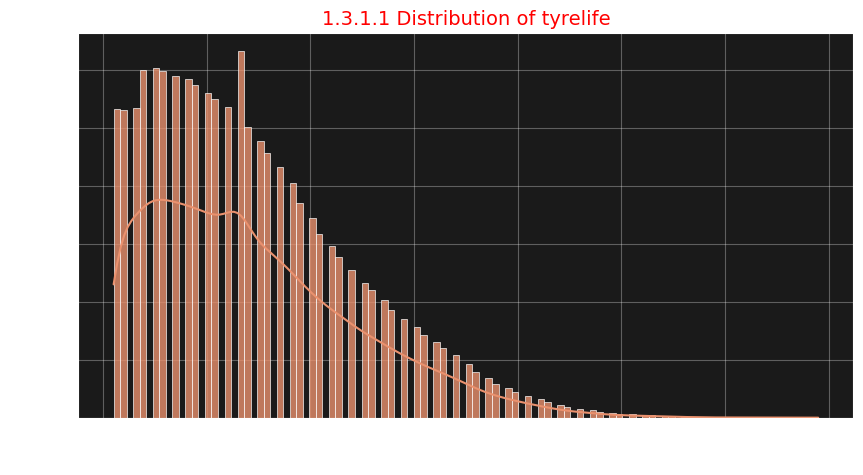

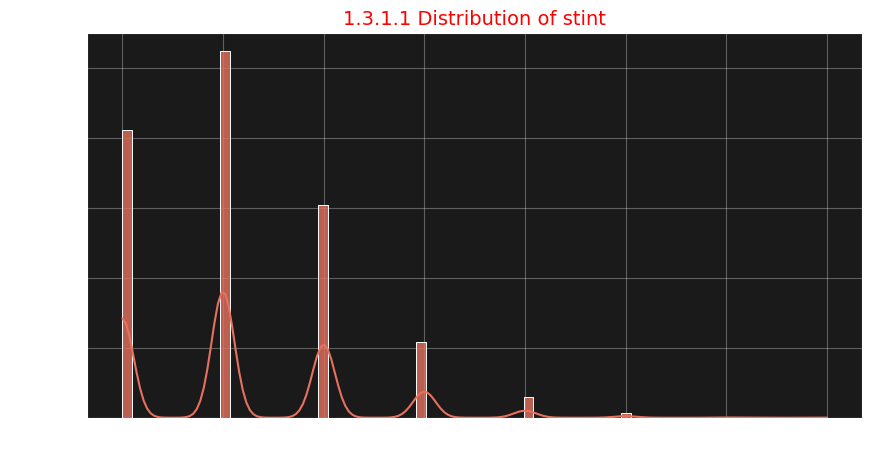

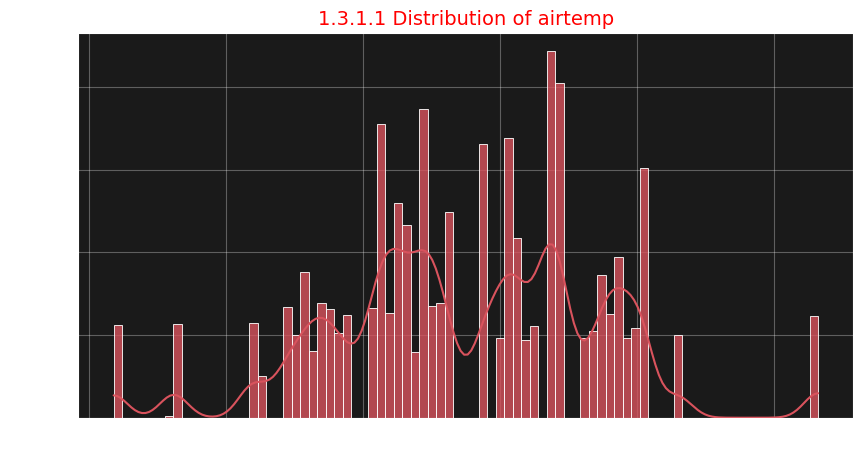

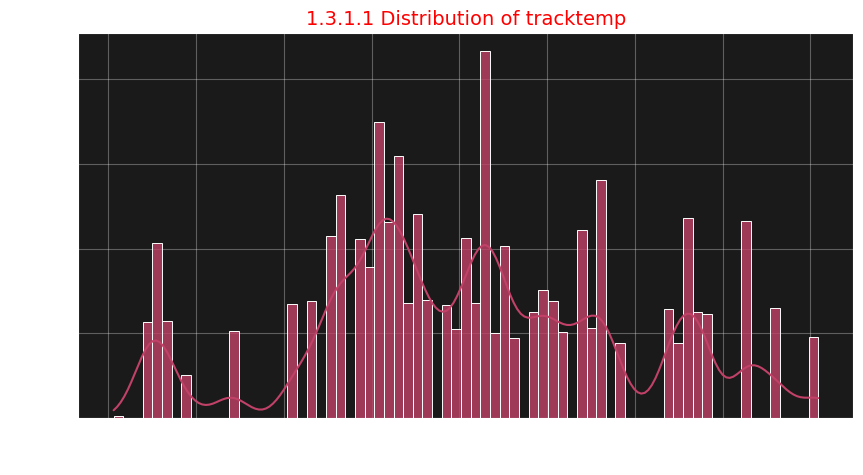

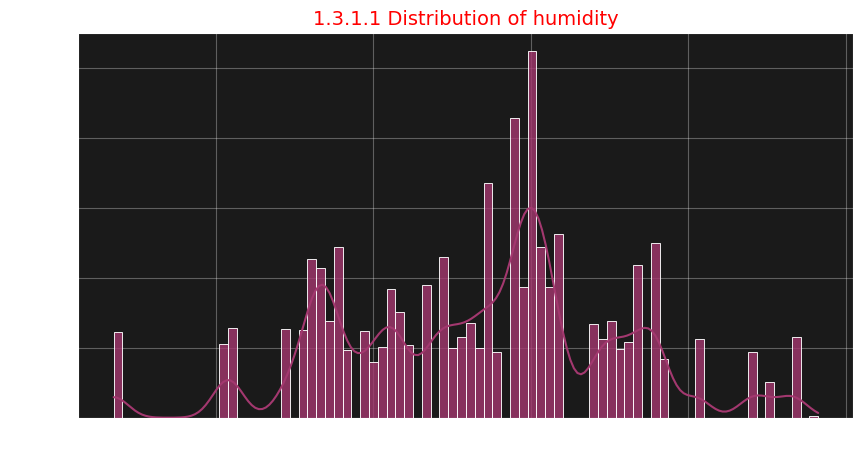

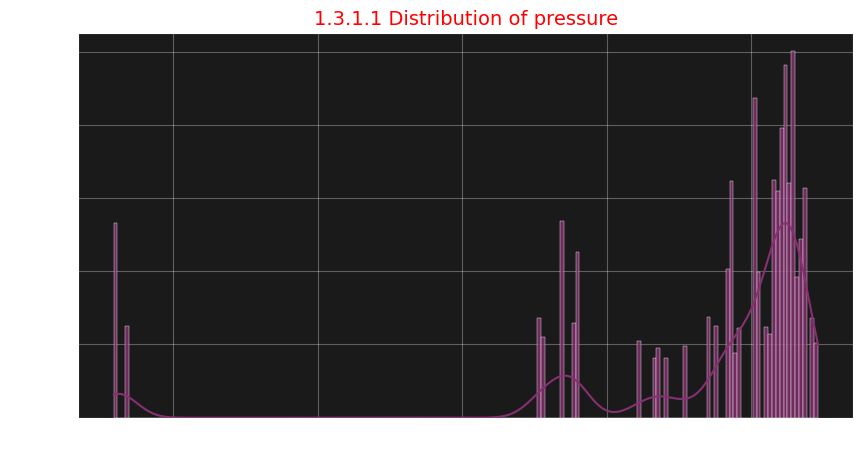

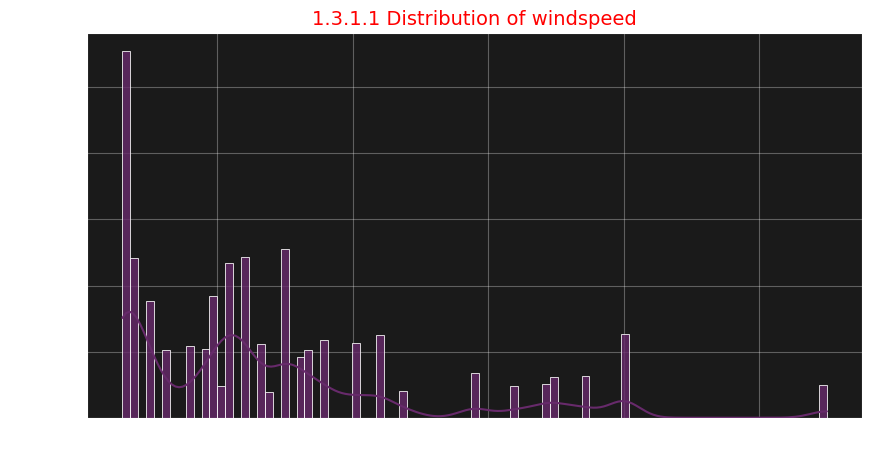

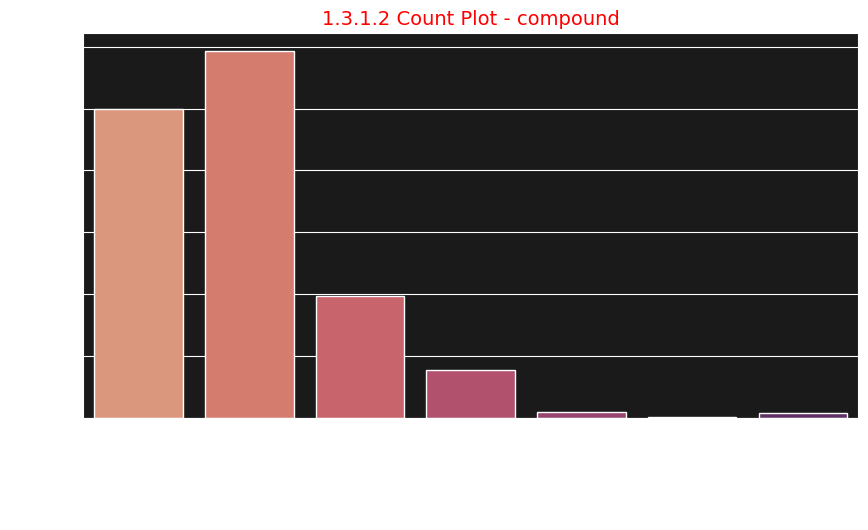

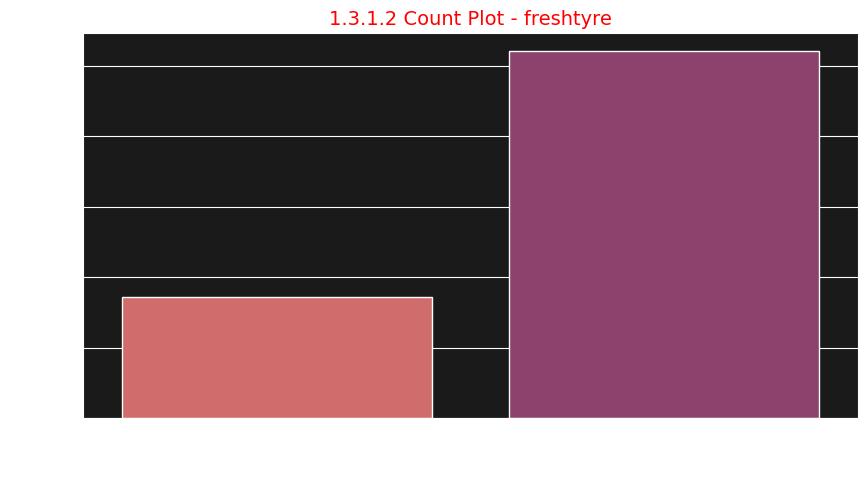


1.3.1.3 Skewness and Kurtosis


,Skewness,Kurtosis
tyrelife,0.898000,0.551000
stint,0.895000,0.896000
airtemp,-0.116000,0.145000
tracktemp,0.051000,-0.350000
humidity,-0.142000,-0.122000
pressure,-2.641000,6.651000
windspeed,1.449000,1.939000


In [ ]:
print("=== 1.3.1 Univariate Analysis ===")

sns.set_style("darkgrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.facecolor'] = '#1a1a1a'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

print(" 1.3.1 Univariate Analysis ")

num_cols = ['tyrelife', 'stint', 'airtemp', 'tracktemp', 'humidity', 'pressure', 'windspeed']
cat_cols = ['compound', 'freshtyre']

# 1.3.1.1 Distribution of numerical features
palette = sns.color_palette("flare", len(num_cols))
for i, col in enumerate(num_cols):
    plt.figure()
    sns.histplot(df[col], kde=True, color=palette[i], alpha=0.8, edgecolor='white')
    plt.title(f'1.3.1.1 Distribution of {col}', fontsize=14, color='red')
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.show()

# 1.3.1.2 Count plots for categorical features
for col in cat_cols:
    plt.figure()
    sns.countplot(data=df, x=col, palette="flare")
    plt.title(f'1.3.1.2 Count Plot - {col}', fontsize=14, color='red')
    plt.xticks(rotation=45, color='white')
    plt.yticks(color='white')
    plt.show()

# 1.3.1.3 Skewness & Kurtosis
print("\n1.3.1.3 Skewness and Kurtosis")
skew = df[num_cols].skew().round(3)
kurt = df[num_cols].kurtosis().round(3)
stats_df = pd.DataFrame({'Skewness': skew, 'Kurtosis': kurt})
display(stats_df.style.background_gradient(cmap='Reds'))





**Bivariate Analysis**

 1.3.2 Bivariate Analysis


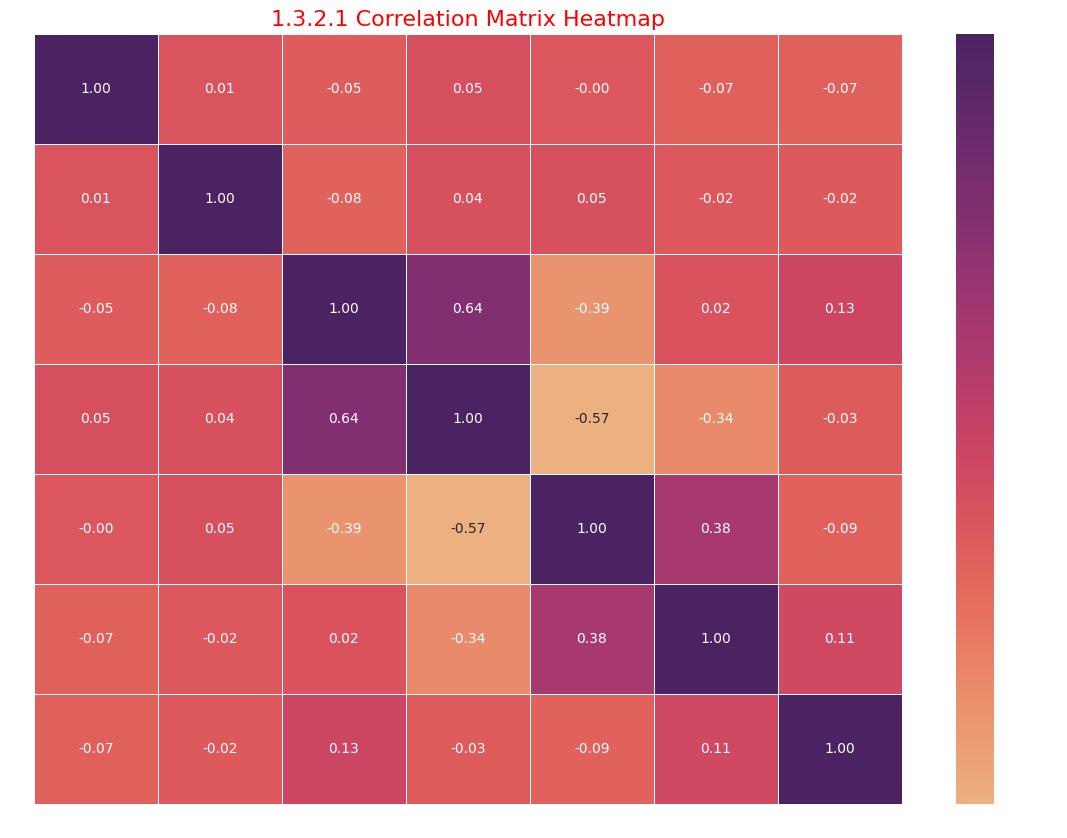

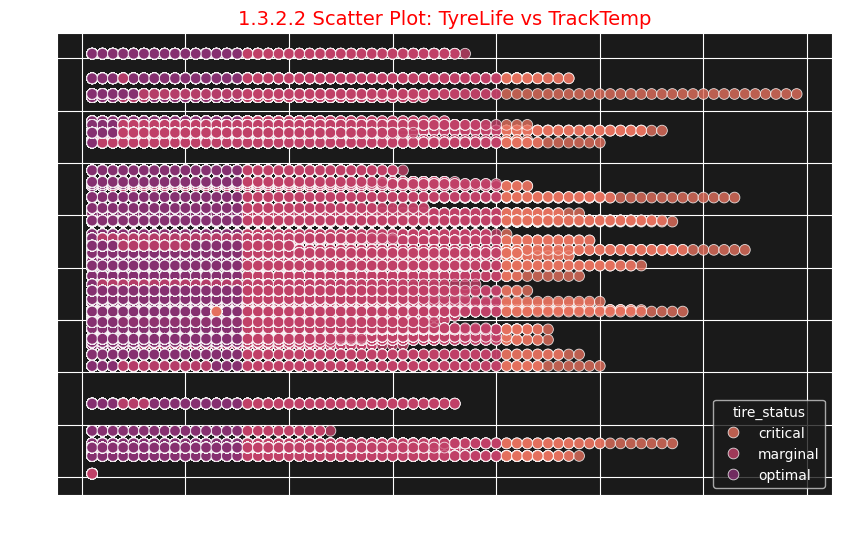

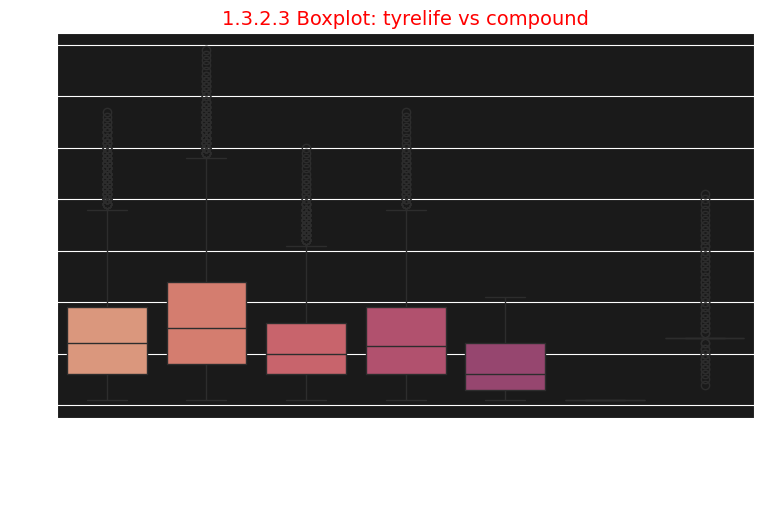

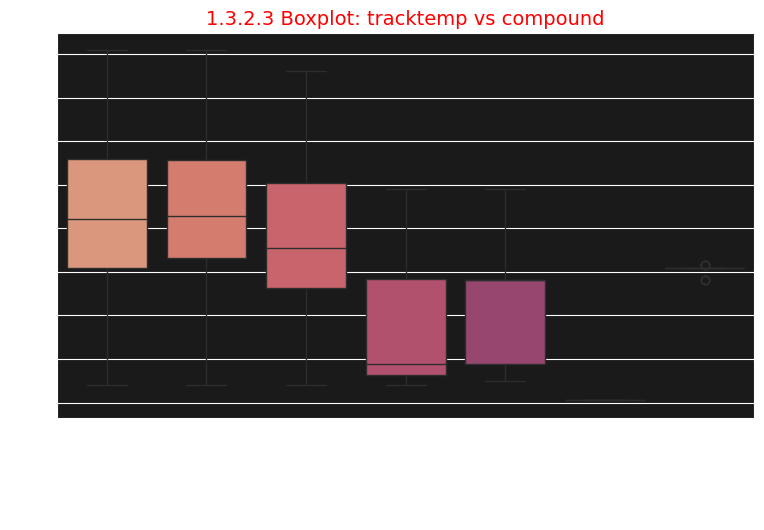

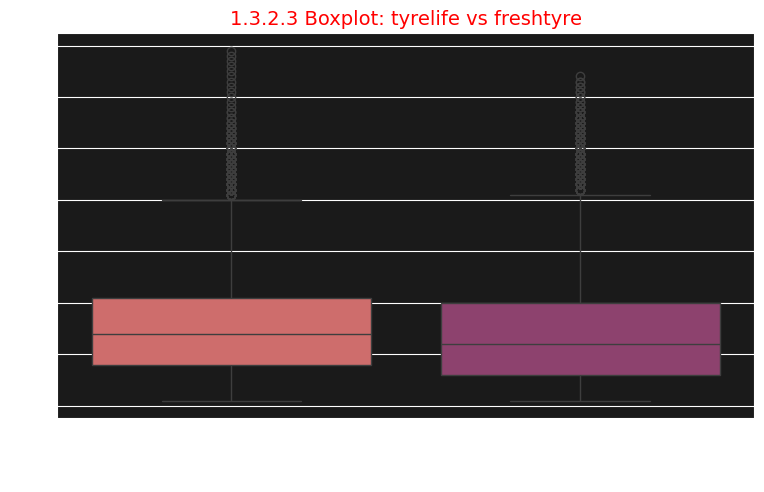

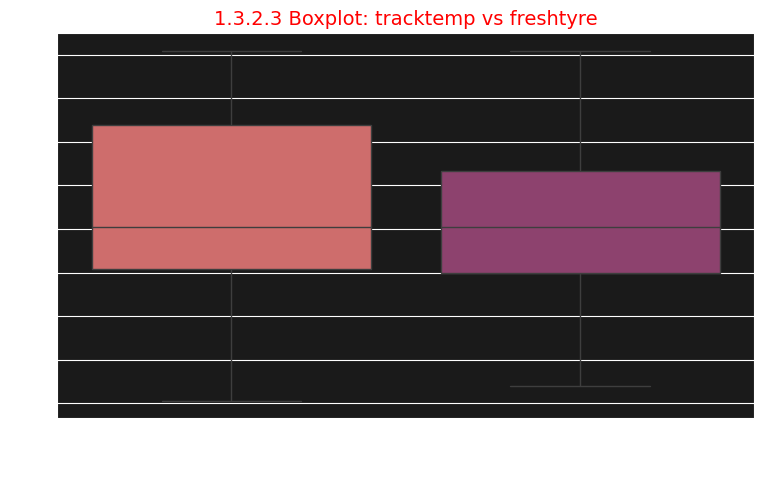

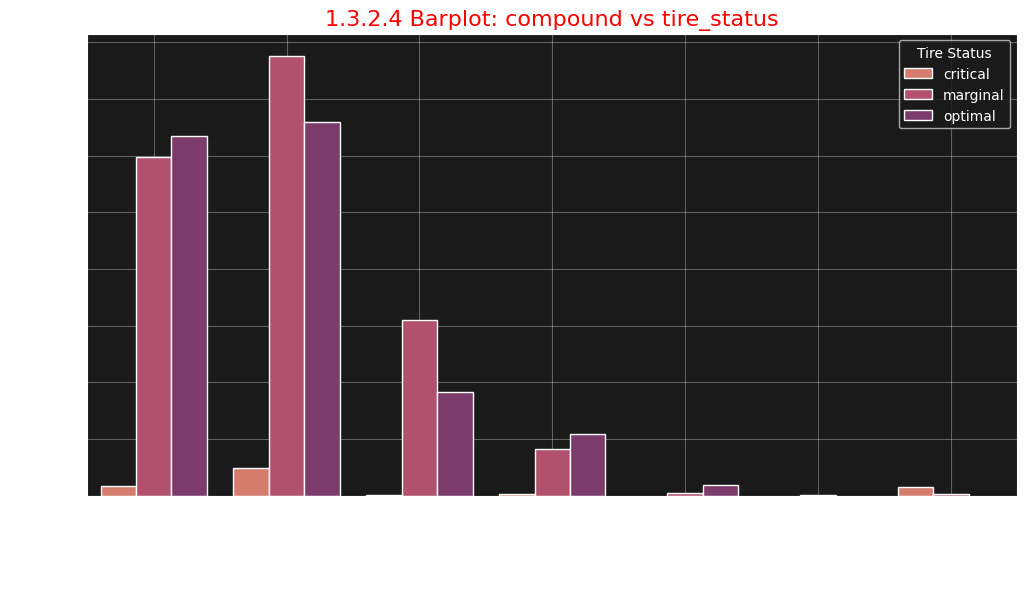

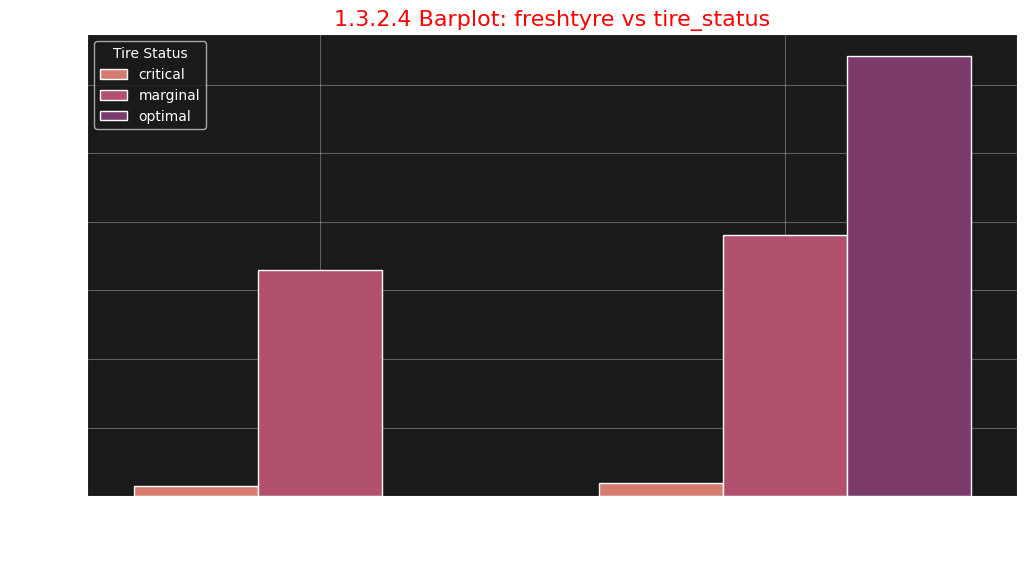

In [ ]:


sns.set_style("darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.facecolor'] = '#1a1a1a'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

print(" 1.3.2 Bivariate Analysis")

num_cols = ['tyrelife', 'stint', 'airtemp', 'tracktemp', 'humidity', 'pressure', 'windspeed']
cat_cols = ['compound', 'freshtyre']

# 1.3.2.1 Correlation matrix Heatmap
plt.figure(figsize=(14, 10))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='flare', fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Correlation'})
plt.title('1.3.2.1 Correlation Matrix Heatmap', fontsize=16, color='red')
plt.show()

# 1.3.2.2 Scatter plots
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='tyrelife', y='tracktemp', hue='tire_status', palette='flare', alpha=0.8, s=60)
plt.title('1.3.2.2 Scatter Plot: TyreLife vs TrackTemp', fontsize=14, color='red')
plt.show()

# 1.3.2.3 Boxplot (categorical vs numerical)
for cat in cat_cols:
    for num in ['tyrelife', 'tracktemp']:
        plt.figure(figsize=(9,5))
        sns.boxplot(x=cat, y=num, data=df, palette='flare')
        plt.title(f'1.3.2.3 Boxplot: {num} vs {cat}', fontsize=14, color='red')
        plt.xticks(rotation=45)
        plt.show()

# 1.3.2.4 & 1.3.2.5 Barplot
palette = sns.color_palette("flare", 3)

for cat in ['compound', 'freshtyre']:
    plt.figure(figsize=(12, 6))
    sns.countplot(data=df, x=cat, hue='tire_status', palette=palette)
    plt.title(f'1.3.2.4 Barplot: {cat} vs tire_status', fontsize=16, color='red')
    plt.xlabel(cat, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.xticks(rotation=45)
    plt.legend(title='Tire Status')
    plt.grid(True, alpha=0.3)
    plt.show()


**Multivariate Analysis**

In [ ]:
print(" 1.3.3 Multivariate Analysis ")

# 1.3.3.1 3D Scatter Plot
sample_df = df.sample(8000, random_state=42)
fig = px.scatter_3d(sample_df,
                    x='tyrelife',
                    y='tracktemp',
                    z='airtemp',
                    color='tire_status',
                    color_discrete_sequence=px.colors.sequential.Reds_r,
                    title='1.3.3.1 3D Scatter Plot - Tyre Status',
                    opacity=0.8,
                    width=1000, height=700)
fig.update_layout(scene=dict(bgcolor='#1a1a1a'),
                  title_font_color='red',
                  paper_bgcolor='#1a1a1a',
                  font_color='white')
fig.show()

# 1.3.3.2 VIF Table
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_num = df[num_cols].fillna(0)
vif_data = pd.DataFrame()
vif_data["feature"] = X_num.columns
vif_data["VIF"] = [variance_inflation_factor(X_num.values, i) for i in range(len(X_num.columns))]

print("\n1.3.3.2 Check Multicollinearity (VIF)")
display(vif_data.round(2).style.background_gradient(cmap='Reds'))

# 1.3.3.3 PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_num)
df['pca1'] = pca_result[:,0]
df['pca2'] = pca_result[:,1]



 1.3.3 Multivariate Analysis 



1.3.3.2 Check Multicollinearity (VIF)


,feature,VIF
0,tyrelife,3.130000
1,stint,5.430000
2,airtemp,51.520000
3,tracktemp,34.390000
4,humidity,17.190000
5,pressure,76.200000
6,windspeed,2.770000


# **data preprocc**

In [ ]:
print(" 1.4 Data Preprocessing ")

# 1.4.1 Encoding Categorical Variables
print("1.4.1 Encoding Categorical Variables")
cat_cols = ['compound', 'freshtyre']
df_encoded = pd.get_dummies(df[cat_cols + ['tyrelife', 'stint', 'airtemp', 'tracktemp',
                                           'humidity', 'pressure', 'windspeed', 'tire_status']],
                            columns=cat_cols, drop_first=True)
print(" One-Hot Encoding done")

# 1.4.2 Feature Scaling
print("1.4.2 Feature Scaling")
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

num_cols = ['tyrelife', 'stint', 'airtemp', 'tracktemp', 'humidity', 'pressure', 'windspeed']
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])
print(" Features scaled successfully")

# 1.4.3 Outlier Detection & Treatment (Capping)
print("1.4.3 Outlier Detection & Treatment")
for col in num_cols:
    Q1 = df_encoded[col].quantile(0.25)
    Q3 = df_encoded[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_encoded[col] = df_encoded[col].clip(lower, upper)

print(" Outliers capped using IQR method")

# 1.4.4 Handle Imbalanced Data (SMOTE)
print("1.4.4 Handle Imbalanced Data")
from imblearn.over_sampling import SMOTE
X = df_encoded.drop('tire_status', axis=1)
y = df_encoded['tire_status']

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print(" Imbalanced data handled with SMOTE")
print("New class distribution:")
print(y_resampled.value_counts(normalize=True) * 100)

# 1.4.5 Train & Test Split
print("1.4.5 Train & Test Split")
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled,
                                                    test_size=0.2, random_state=42,
                                                    stratify=y_resampled)

print(f"Train set: {X_train.shape[0]:,} rows")
print(f"Test set:  {X_test.shape[0]:,} rows")


 1.4 Data Preprocessing 
1.4.1 Encoding Categorical Variables
 One-Hot Encoding done
1.4.2 Feature Scaling
 Features scaled successfully
1.4.3 Outlier Detection & Treatment
 Outliers capped using IQR method
1.4.4 Handle Imbalanced Data
 Imbalanced data handled with SMOTE
New class distribution:
tire_status
critical    33.333333
marginal    33.333333
optimal     33.333333
Name: proportion, dtype: float64
1.4.5 Train & Test Split
Train set: 85,159 rows
Test set:  21,290 rows


# **AI Tasks**

**clustring**

In [ ]:
!pip install scikit-fuzzy

In [ ]:
import skfuzzy as fuzz
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("=== 2.1 Clustering (Fuzzy C-Means Style) ===")

# 2.1.1 Remove target labels
X_cluster_numeric = X_cluster.select_dtypes(include=[np.number]).copy()
X_cluster_final = X_cluster_numeric.values.astype(np.float64)
X_cluster_final = np.nan_to_num(X_cluster_final)

print(f" Ready for Clustering. Shape: {X_cluster_final.shape}")

# 2.1.2 Apply Fuzzy C-Means
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    X_cluster_final.T, c=3, m=2, error=0.005, maxiter=1000, init=None
)

# Conv Fuzzy membership to Hard clusters for evaluation purposes
clusters = np.argmax(u, axis=0)

# 2.2 Evaluation Metrics
sil_score = silhouette_score(X_cluster, clusters)
dbi_score = davies_bouldin_score(X_cluster, clusters)

print(f"2.2.1 Silhouette Score   : {sil_score:.4f}  ")
print(f"2.2.2 Davies-Bouldin Index: {dbi_score:.4f}  ")
print(f"2.2.3 Fuzzy Partition Coef: {fpc:.4f}  ")

=== 2.1 Clustering (Fuzzy C-Means Style) ===
 Ready for Clustering. Shape: (106449, 7)
2.2.1 Silhouette Score   : 0.1798  
2.2.2 Davies-Bouldin Index: 1.8247  
2.2.3 Fuzzy Partition Coef: 0.3864  


**classifcation**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

print("\n 2.3 Classification (Random Forest) ")

# 2.3.1 & 2.3.2 Train model

clf = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42)
clf.fit(X_train, y_train)

# pred
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)

# 2.4 Evaluation Metrics
print("\n2.4 Evaluation Metrics:")
print(f"2.4.1 Accuracy      : {accuracy_score(y_test, y_pred):.4f}")
print(f"2.4.2 F1-Score      : {f1_score(y_test, y_pred, average='weighted'):.4f}")
print(f"2.4.3 ROC-AUC       : {roc_auc_score(y_test, y_proba, multi_class='ovr'):.4f}")

print("\n2.4.4 Classification Report:")
print(classification_report(y_test, y_pred))



 2.3 Classification (Random Forest) 

2.4 Evaluation Metrics:
2.4.1 Accuracy      : 0.9974
2.4.2 F1-Score      : 0.9974
2.4.3 ROC-AUC       : 0.9988

2.4.4 Classification Report:
              precision    recall  f1-score   support

    critical       0.99      1.00      1.00      7096
    marginal       1.00      0.99      1.00      7097
     optimal       1.00      1.00      1.00      7097

    accuracy                           1.00     21290
   macro avg       1.00      1.00      1.00     21290
weighted avg       1.00      1.00      1.00     21290



# **Extra tasks**

**Originally, my project was designed to predict how many turns a tire will last.**

**Classification (Extra Model - XGBoost)**

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score


# We need to convert the labels to numbers (0, 1, 2) because XGBoost requires this.
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Model definition and training
xgb_clf = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_clf.fit(X_train, y_train_encoded)

# Forecasts and Assessment
y_pred_xgb = xgb_clf.predict(X_test)
xgb_acc = accuracy_score(y_test_encoded, y_pred_xgb)

print(f"XGBoost Accuracy: {xgb_acc:.4f}")
print(f"Random Forest Accuracy: 0.9974 (Previous)")

# Comparison logic
if xgb_acc > 0.9974:
    print("Result: XGBoost outperformed Random Forest.")
else:
    print("Result: Random Forest maintained a slight lead or equal performance.")

XGBoost Accuracy: 0.9975
Random Forest Accuracy: 0.9974 (Previous)
Result: XGBoost outperformed Random Forest.


**Regression**

In [ ]:
# Preparation using the original data (before SMOTE)
# We will use df, which is the clean data that we first performed dropna on.
X_reg = df.drop(columns=['tire_status', 'tyrelife'], errors='ignore')
X_reg = X_reg.select_dtypes(include=[np.number])
y_reg = df['tyrelife']

# Re-dividing the data for regeneration
from sklearn.model_selection import train_test_split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# train
from sklearn.ensemble import RandomForestRegressor
reg_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
reg_model.fit(X_train_r, y_train_r)

# pred
y_pred_r = reg_model.predict(X_test_r)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print(f"MAE: {mean_absolute_error(y_test_r, y_pred_r):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_r)):.2f}")
print(f"R2 Score: {r2_score(y_test_r, y_pred_r):.4f}")

MAE: 2.82
RMSE: 4.48
R2 Score: 0.7976


In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np

def predict_tire_performance(tyrelife, stint, tracktemp, humidity, airtemp, pressure):
    try:

        data = {
            'tyrelife': [tyrelife],
            'stint': [stint],
            'tracktemp': [tracktemp],
            'humidity': [humidity],
            'airtemp': [airtemp],
            'pressure': [pressure],
            'windspeed': [0]
        }
        input_df = pd.DataFrame(data)
        for col in X_train.columns:
            if col not in input_df.columns:
                input_df[col] = 0


        input_df = input_df[X_train.columns]


        status_idx = xgb_clf.predict(input_df)[0]
        status_label = le.inverse_transform([status_idx])[0]


        rem_life = reg_model.predict(input_df)[0]

        return f"Status: {status_label.upper()}", f"{rem_life:.1f} Laps"

    except Exception as e:
        return f"Error: {str(e)}", "Check Logic"


with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🏎️ Ferrari Tire Performance Predictor")
    gr.Markdown("Enter telemetry data to check tire health in real-time.")

    with gr.Row():
        with gr.Column():
            tyrelife = gr.Number(label="Current Lap (TyreLife)", value=10)
            stint = gr.Number(label="Current Stint", value=1)
            pressure = gr.Slider(20, 30, label="Tire Pressure (PSI)", value=24)
        with gr.Column():
            tracktemp = gr.Slider(10, 60, label="Track Temp (°C)", value=35)
            humidity = gr.Slider(0, 100, label="Humidity (%)", value=40)
            airtemp = gr.Slider(10, 45, label="Air Temp (°C)", value=25)

    btn = gr.Button("Analyze Performance", variant="primary")

    with gr.Row():
        output_status = gr.Textbox(label="Classification Result (XGBoost)")
        output_life = gr.Textbox(label="Regression Forecast (Laps)")

    btn.click(predict_tire_performance,
              inputs=[tyrelife, stint, tracktemp, humidity, airtemp, pressure],
              outputs=[output_status, output_life])


demo.launch(share=True)